# ChronoClone tutorial: identifying metaclones

A metaclone is a group of clones with similar cell-state changes over time. This tutorial uses the Weinreb 2020 dataset and follows the supplied `0010_ChronoClone_Weinreb2020.ipynb` workflow.

We will filter clones, identify metaclones, and examine the annotation UMAPs, silhouette scores, consensus heatmap, clone counts, cell-state dynamics, Day-2 gene expression, and density UMAP from the supplied workflow. The inputs contain metadata, saved UMAP coordinates, and Day-2 expression; they have no preassigned metaclones. See the [data notes](../examples/weinreb/data/README.md) for its source and filtering history.

## Setup

Run this notebook from a clone of the repository. The [example guide](../examples/weinreb/README.md) explains installation.

Recorded MacBook environment: **chronoclone** at `/Users/HiroMacBook/Documents/ChronoClone/.runtime/chronoclone`, kernel **chronoclone-paper**. This existing environment is reused without changing installed packages. The next cell prints the Python and package versions and the local execution command.

The plot types follow the original notebook. This tutorial computes a fresh deterministic fit; its metaclone IDs and results differ from the historical outputs saved in the original. Each plot is shown separately with editable SVG output.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, tempfile
from importlib.metadata import version
sys.dont_write_bytecode = True
os.environ.setdefault('NUMBA_CACHE_DIR', str(Path(tempfile.gettempdir())/'chronoclone-numba-cache'))
# Find the package checkout when run from either tutorial location.
parents = [Path.cwd(), *Path.cwd().parents]
REPO = next(q for p in parents for q in (p, p/'ChronoClone')
            if (q/'chronoclone/__init__.py').is_file())
sys.path.insert(0, str(REPO))
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.neighbors import NearestNeighbors
from IPython.display import display
import chronoclone as cc
sc.settings.n_jobs = os.cpu_count() or 1
DAYS = [2, 4, 6]
DATA = REPO/'examples/weinreb/data'
OUT = REPO/'examples/weinreb/results'
OUT.mkdir(parents=True, exist_ok=True)
DYNAMICS = OUT/'metaclone_dynamics'
DYNAMICS.mkdir(parents=True, exist_ok=True)
versions = {name:version(name) for name in ['numpy','pandas','scipy','anndata','scanpy',
            'scikit-learn','matplotlib','igraph','leidenalg']}
versions['chronoclone'] = cc.__version__
print({'environment':'chronoclone','path':sys.prefix,'kernel':'chronoclone-paper',
       'manager':'Existing installation reused through a local alias',
       'python':sys.version.split()[0],'available_cores':os.cpu_count()})
display(pd.Series(versions, name='version').to_frame())
print('Original MacBook execution command:')
print(f'JUPYTER_PATH=/Users/HiroMacBook/Documents/ChronoClone/.runtime/jupyter {sys.executable} -m nbconvert --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper --ExecutePreprocessor.timeout=1800 {REPO}/notebooks/chronoclone_tutorial.ipynb')


{'environment': 'chronoclone', 'path': '/Users/HiroMacBook/Documents/ChronoClone/.runtime/chronoclone', 'kernel': 'chronoclone-paper', 'manager': 'Existing installation reused through a local alias', 'python': '3.11.15', 'available_cores': 12}


,version
numpy,2.4.6
pandas,2.3.3
scipy,1.17.1
anndata,0.12.18
scanpy,1.11.5
scikit-learn,1.9.0
matplotlib,3.11.0
igraph,1.0.0
leidenalg,0.12.0
chronoclone,0.1.0


Original MacBook execution command:
JUPYTER_PATH=/Users/HiroMacBook/Documents/ChronoClone/.runtime/jupyter /Users/HiroMacBook/Documents/ChronoClone/.runtime/chronoclone/bin/python -m nbconvert --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper --ExecutePreprocessor.timeout=1800 /Users/HiroMacBook/Documents/ChronoClone/ChronoClone/notebooks/chronoclone_tutorial.ipynb


## 1. Load the cell data

Restore the recorded category order and UMAP coordinates. Gene-expression values are unnecessary for identifying metaclones from these cell-state annotations.

In [2]:
provenance = json.loads((DATA/'provenance.json').read_text())
input_path = DATA/provenance['payload']['file']
input_sha = hashlib.sha256(input_path.read_bytes()).hexdigest()
assert input_sha == provenance['payload']['sha256']
cells = pd.read_csv(input_path, **provenance['extraction']['read_csv']).set_index('cell_id')
for column, schema in provenance['extraction']['source_categorical_schema'].items():
    cells[column] = pd.Categorical(cells[column], categories=schema['categories'], ordered=schema['ordered'])
assert cells.index.is_unique and cells['LARRY_ID'].notna().all()
obs = cells[['LARRY_ID','day','cell_type']].copy()
obs['day'] = obs['day'].astype(int)
obs['condition'] = 'Weinreb'
adata = ad.AnnData(X=sparse.csr_matrix((len(obs),0),dtype=np.float32), obs=obs)
adata.obsm['X_umap'] = cells[['UMAP1','UMAP2']].to_numpy(dtype=np.float32)
print(f'{adata.n_obs:,} cells; {adata.obs.LARRY_ID.nunique():,} clones')
display(adata.obs.groupby('day',observed=True).size().rename('cells').to_frame())


9,714 cells; 784 clones


,cells
day,
2,1041
4,3301
6,5372


### View the original cell-state annotations

These views use the full annotation cohort before continuity filtering.

In [3]:
# Verify the additional source projections used by the original plots.
plot_inputs = json.loads((DATA/'plot_inputs.json').read_text())
for payload in [plot_inputs['annotation_umap'],plot_inputs['day2_expression']]:
    path = DATA/payload['file']
    assert hashlib.sha256(path.read_bytes()).hexdigest() == payload['sha256']
annotation_cells = pd.read_csv(DATA/'weinreb_annotation_umap.csv.gz',
    dtype={'cell_id':str,'cell_type':str,'UMAP1':'float32','UMAP2':'float32'},
    keep_default_na=False).set_index('cell_id')
assert annotation_cells.index.is_unique
print(f'{len(annotation_cells):,} cells in the original annotation background')


126,861 cells in the original annotation background


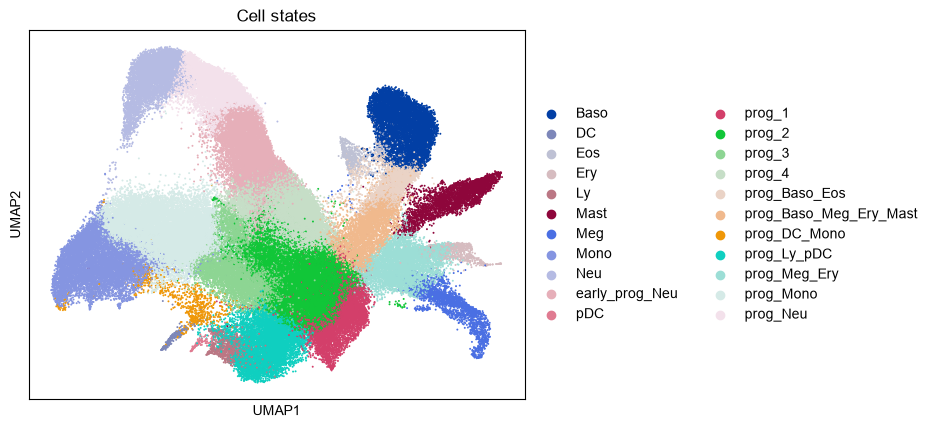

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/cell_state_umap


In [4]:
# Select states and coordinates for this original annotation view.
plot_cells = annotation_cells
coordinates = plot_cells[['UMAP1','UMAP2']].to_numpy(dtype=np.float32)
state_order = plot_inputs['annotation_umap']['category_order']
if not True:
    state_order = [state for state in state_order if plot_cells['cell_type'].eq(state).any()]
state_colors = plot_inputs['annotation_umap']['palette_by_label']
selected_states = state_order
plot_obs = pd.DataFrame(index=plot_cells.index)
plot_obs['cell_type'] = pd.Categorical(plot_cells['cell_type'],categories=state_order)
annotation_view = ad.AnnData(X=sparse.csr_matrix((len(plot_obs),0)),obs=plot_obs)
annotation_view.obsm['X_umap'] = coordinates
annotation_view.uns['cell_type_colors'] = [state_colors[state] for state in state_order]
with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'Arial'}):
    fig, ax = plt.subplots(figsize=(6.4,4.8))
    sc.pl.umap(annotation_view,color='cell_type',groups=selected_states,
        s=8,legend_loc="right margin",
        title='Cell states',ax=ax,show=False)
    stem = OUT/'cell_state_umap'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=200,bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Terminal states

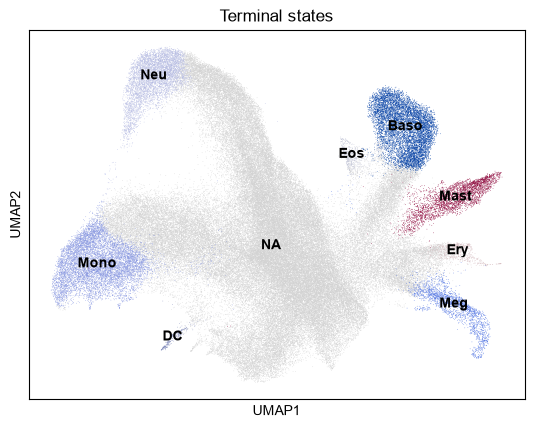

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/terminal_state_umap


In [5]:
# Select states and coordinates for this original annotation view.
plot_cells = annotation_cells
coordinates = plot_cells[['UMAP1','UMAP2']].to_numpy(dtype=np.float32)
state_order = plot_inputs['annotation_umap']['category_order']
if not True:
    state_order = [state for state in state_order if plot_cells['cell_type'].eq(state).any()]
state_colors = plot_inputs['annotation_umap']['palette_by_label']
selected_states = ['Baso','DC','Eos','Ery','Mast','Meg','Mono','Neu']
plot_obs = pd.DataFrame(index=plot_cells.index)
plot_obs['cell_type'] = pd.Categorical(plot_cells['cell_type'],categories=state_order)
annotation_view = ad.AnnData(X=sparse.csr_matrix((len(plot_obs),0)),obs=plot_obs)
annotation_view.obsm['X_umap'] = coordinates
annotation_view.uns['cell_type_colors'] = [state_colors[state] for state in state_order]
with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'Arial'}):
    fig, ax = plt.subplots(figsize=(6.4,4.8))
    sc.pl.umap(annotation_view,color='cell_type',groups=selected_states,
        s=120000/len(plot_cells),legend_loc="on data",
        title='Terminal states',ax=ax,show=False)
    stem = OUT/'terminal_state_umap'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=200,bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Starting progenitor states

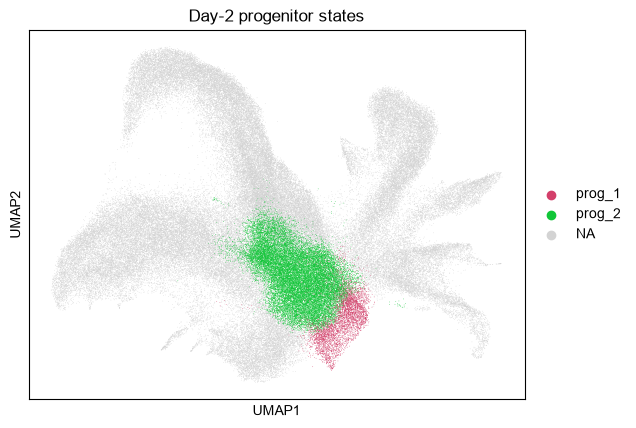

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/progenitor_umap


In [6]:
# Select states and coordinates for this original annotation view.
plot_cells = annotation_cells
coordinates = plot_cells[['UMAP1','UMAP2']].to_numpy(dtype=np.float32)
state_order = plot_inputs['annotation_umap']['category_order']
if not True:
    state_order = [state for state in state_order if plot_cells['cell_type'].eq(state).any()]
state_colors = plot_inputs['annotation_umap']['palette_by_label']
selected_states = ['prog_1','prog_2']
plot_obs = pd.DataFrame(index=plot_cells.index)
plot_obs['cell_type'] = pd.Categorical(plot_cells['cell_type'],categories=state_order)
annotation_view = ad.AnnData(X=sparse.csr_matrix((len(plot_obs),0)),obs=plot_obs)
annotation_view.obsm['X_umap'] = coordinates
annotation_view.uns['cell_type_colors'] = [state_colors[state] for state in state_order]
with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'Arial'}):
    fig, ax = plt.subplots(figsize=(6.4,4.8))
    sc.pl.umap(annotation_view,color='cell_type',groups=selected_states,
        s=120000/len(plot_cells),legend_loc="right margin",
        title='Day-2 progenitor states',ax=ax,show=False)
    stem = OUT/'progenitor_umap'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=200,bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


## 2. Keep clones with consecutive recovery

Start with Day-2 progenitor states `prog_1` and `prog_2`, and require recovery at two or more consecutive time points. The included cohort has already passed this filter; this step checks it again.

In [7]:
adata_filtered = cc.filter_lineage_continuity(
    adata, condition_key='condition', condition_val='Weinreb', day_key='day',
    cell_type_key='cell_type', start_cell_type=['prog_1','prog_2'],
    barcode_key='LARRY_ID', min_persistence=2)
print(f'{adata_filtered.n_obs:,} cells; {adata_filtered.obs.LARRY_ID.nunique():,} clones after filtering')


Starting lineage filtration for Condition: 'Weinreb'...
Start cell type(s): {'prog_1', 'prog_2'}
Detected time points: [np.int64(2), np.int64(4), np.int64(6)]
Valid Start barcodes at Day 2: 784
Barcodes passing continuity filter (min 2 timepoints): 784

VERIFICATION REPORT
Original Cells : 9714
Filtered Cells : 9714 (100.00%)

Day 2 Composition:
cell_type
prog_2                    786
prog_1                    255
prog_Mono                   0
prog_Meg_Ery                0
prog_Ly_pDC                 0
prog_DC_Mono                0
prog_Baso_Meg_Ery_Mast      0
prog_Baso_Eos               0
prog_4                      0
prog_3                      0
Baso                        0
DC                          0
early_prog_Neu              0
Neu                         0
Mono                        0
Meg                         0
Mast                        0
Ly                          0
Ery                         0
Eos                         0
prog_Neu                    0
Name: count,

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/chronoclone/preprocessing.py:150: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(barcode_key)[day_key]


## 3. Build and normalize clone trajectories

Count cells for each clone, day, and cell state. Then divide by each clone's total cell count at that day. The resulting vector describes how the clone's cell-state composition changes over time.

In [8]:
states = sorted(str(x) for x in adata_filtered.obs['cell_type'].unique())
clone_table = cc.build_clone_table(
    adata_filtered, clone_id_col='LARRY_ID', time_col='day', feature_col='cell_type',
    time_prefix='Day', feature_prefix='', times_order=DAYS, features_order=states,
    min_total_count=0)
normalized = cc.normalize_clone_table(
    clone_table, times_order=[f'Day{day}' for day in DAYS], features_order=states,
    time_prefix='Day', feature_prefix='')
for day in DAYS:
    totals = normalized.filter(regex=f'^Day{day}_').sum(axis=1)
    assert np.all(np.isclose(totals,0) | np.isclose(totals,1))
print(f'{len(normalized):,} clones × {len(normalized.columns)} trajectory features')
display(normalized.iloc[:5,:8])


784 clones × 44 trajectory features


/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/chronoclone/preprocessing.py:260: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby([clone_id_col, feature_col])
/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/chronoclone/preprocessing.py:260: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby([clone_id_col, feature_col])
/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/chronoclone/preprocessing.py:260: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to ad

,Day2_prog_1,Day2_prog_2,Day4_Baso,Day4_DC,Day4_Eos,Day4_Ery,Day4_Ly,Day4_Mast
LARRY_ID,,,,,,,,
Clone_10,1.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
Clone_15,0.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.0
Clone_21,0.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.0
Clone_38,0.333333,0.666667,0.0,0.0,0.0,0.0,0.0,0.0
Clone_50,0.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Build a consensus matrix

Keep clones with at least three cells. Run Leiden clustering at several resolutions and count how often each pair of clones is grouped together. The seed is fixed for reproducibility.

In [9]:
resolutions = np.arange(1.1,4.1,0.1)
filtered_table, trajectory_adata, consensus = cc.build_consensus_matrix(
    normalized, min_cells=3, adata_full=adata_filtered, clone_id_col='LARRY_ID',
    n_neighbors=30, resolutions=resolutions, random_state=0)
distance = 1-consensus
assert np.allclose(consensus,consensus.T) and np.allclose(np.diag(consensus),1)
assert (distance>=0).all() and (distance<=1).all()
print(f'Consensus matrix: {consensus.shape[0]} × {consensus.shape[1]} clones')


/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/chronoclone/consensus.py:62: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  clone_counts = adata_full.obs.groupby(clone_id_col).size()


/Users/HiroMacBook/Documents/ChronoClone/.runtime/chronoclone/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/chronoclone/consensus.py:79: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


Consensus matrix: 713 × 713 clones


## 5. Select a clustering threshold

Evaluate distance thresholds from 0.01 to 0.90. ChronoClone selects the threshold with the highest mean silhouette score on the normalized trajectories.

In [10]:
threshold_grid = np.arange(0.01,0.91,0.01)
thresholds, scores, cluster_counts, threshold, labels, clone_silhouettes = cc.sweep_thresholds(
    distance, filtered_table, thresholds=threshold_grid)
sweep = pd.DataFrame({'threshold':thresholds,'silhouette':scores,'metaclones':cluster_counts})
sweep.to_csv(OUT/'threshold_sweep.csv', index=False)
display(sweep.loc[np.isclose(sweep.threshold,threshold)])


Starting threshold sweep...



Selected threshold : 0.73
Max silhouette score: 0.247
Clusters            : 23


,threshold,silhouette,metaclones
72,0.73,0.246683,23


### Threshold sweep

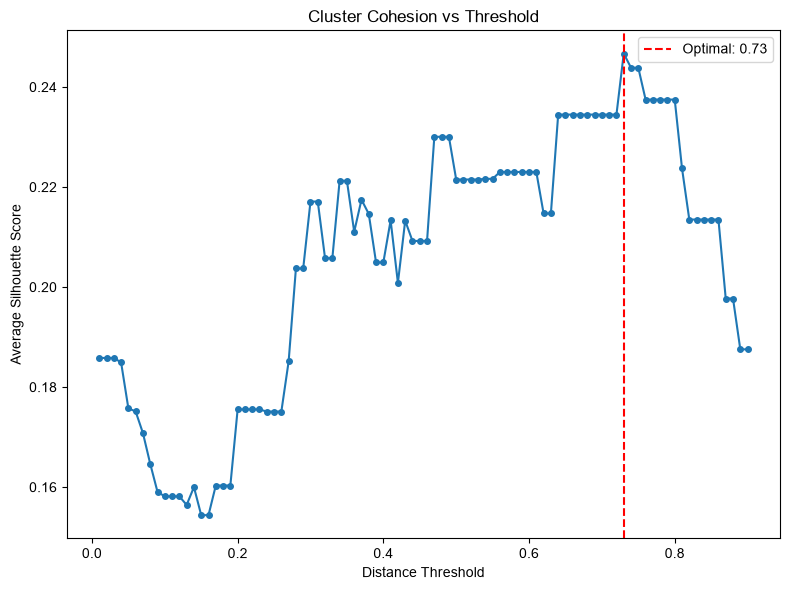

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/threshold_sweep.svg
/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/threshold_sweep.png


In [11]:
# Original threshold-curve construction, split from the paired silhouette plot.
threshold_plot = sweep[['threshold', 'silhouette']].copy()
assert len(threshold_plot) and np.isfinite(threshold_plot.to_numpy(dtype=float)).all()
with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42, 'ps.fonttype': 42,
                     'font.family': 'sans-serif', 'font.sans-serif': ['Arial']}):
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(threshold_plot['threshold'], threshold_plot['silhouette'],
            'o-', color='#1f77b4', markersize=4)
    ax.axvline(x=float(threshold), color='r', linestyle='--',
               label=f'Optimal: {threshold:.2f}')
    ax.set_xlabel('Distance Threshold')
    ax.set_ylabel('Average Silhouette Score')
    ax.set_title('Cluster Cohesion vs Threshold')
    ax.legend()
    fig.tight_layout()
    stem = OUT / 'threshold_sweep'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.pdf'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show()
    print(stem.with_suffix('.svg'))
    print(stem.with_suffix('.png'))


### Silhouette before support filtering

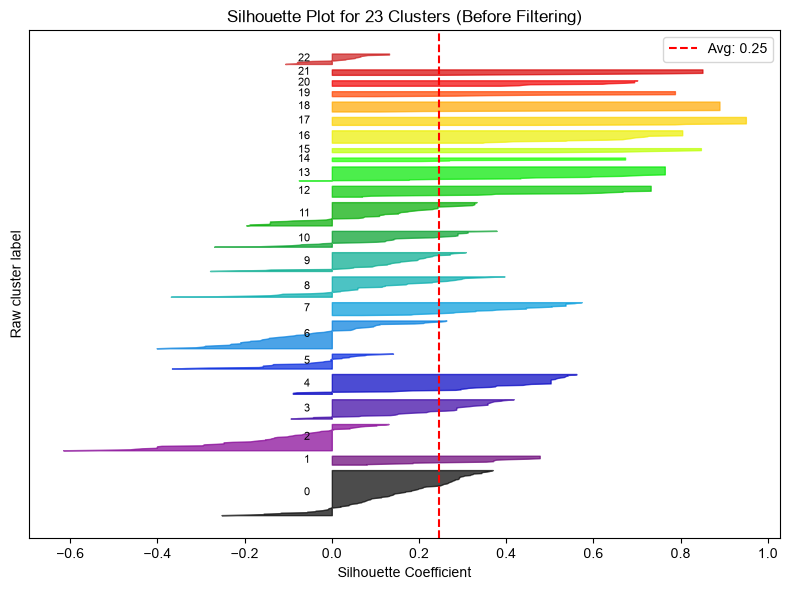

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/silhouette_before_filtering.svg
/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/silhouette_before_filtering.png
{'plotted_clones': 713, 'plotted_clusters': 23, 'mean_of_plotted_silhouettes': 0.2466831128760011}


In [12]:
# Sort each observed raw cluster's original fitted silhouette scores.
# Colour identity is fixed by all raw clusters, and is reused after filtering.
raw_labels_before = np.asarray(labels)
scores_before = np.asarray(clone_silhouettes, dtype=float)
assert raw_labels_before.ndim == scores_before.ndim == 1
assert len(raw_labels_before) == len(scores_before) and np.isfinite(scores_before).all()
raw_ids_before = np.sort(np.unique(raw_labels_before))
assert len(raw_ids_before)
raw_colours_before = {raw: mpl.colormaps['nipy_spectral'](i / len(raw_ids_before))
                      for i, raw in enumerate(raw_ids_before)}
average_before = float(scores_before.mean())
with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42, 'ps.fonttype': 42,
                     'font.family': 'sans-serif', 'font.sans-serif': ['Arial']}):
    fig, ax = plt.subplots(figsize=(8, 6))
    y_lower = 10
    for raw_id in raw_ids_before:
        values = np.sort(scores_before[raw_labels_before == raw_id])
        y_upper = y_lower + len(values)
        colour = raw_colours_before[raw_id]
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, values,
                         facecolor=colour, edgecolor=colour, alpha=0.7)
        ax.text(-0.05, y_lower + 0.5 * len(values), str(raw_id),
                ha='right', va='center', fontsize=8)
        y_lower = y_upper + 10
    ax.axvline(x=average_before, color='red', linestyle='--',
               label=f'Avg: {average_before:.2f}')
    ax.set_title(f'Silhouette Plot for {len(raw_ids_before)} Clusters (Before Filtering)')
    ax.set_xlabel('Silhouette Coefficient')
    ax.set_ylabel('Raw cluster label')
    ax.set_yticks([])
    ax.set_xticks([-0.6, -0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8, 1])
    ax.legend()
    fig.tight_layout()
    stem = OUT / 'silhouette_before_filtering'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show()
    print(stem.with_suffix('.svg'))
    print(stem.with_suffix('.png'))
    print({'plotted_clones': len(scores_before), 'plotted_clusters': len(raw_ids_before),
           'mean_of_plotted_silhouettes': average_before})


## 6. Keep supported metaclones

Keep clones with silhouette scores of at least −0.1 whose original cluster contains at least 15 clones. Count cluster size before filtering individual clones. Number the retained metaclones consecutively and transfer their labels back to cells.

In [13]:
cluster_sizes = pd.Series(labels).value_counts()
size_per_clone = pd.Series(labels).map(cluster_sizes).to_numpy()
keep = (clone_silhouettes >= -0.1) & (size_per_clone >= 15)
label_map = {int(label):i+1 for i,label in enumerate(sorted(np.unique(labels[keep])))}
metaclones = np.array([label_map[int(label)] for label in labels[keep]])
adata = cc.transfer_metaclone_labels(
    adata.copy(), trajectory_adata[keep].copy(), metaclones,
    clone_id_col='LARRY_ID', target_col='metaclone')
assignments = pd.DataFrame({
    'LARRY_ID':filtered_table.index.astype(str), 'raw_cluster':labels,
    'silhouette':clone_silhouettes, 'cluster_size_before_filter':size_per_clone,
    'passes_silhouette':clone_silhouettes>=-0.1, 'passes_cluster_support':size_per_clone>=15,
    'retained':keep,
    'metaclone':[label_map.get(int(label),-1) if retained else -1 for label,retained in zip(labels,keep)]})
assignments.to_csv(OUT/'clone_assignments.csv',index=False)
support = (adata.obs.dropna(subset=['metaclone']).groupby('metaclone',observed=True)
           .agg(clones=('LARRY_ID','nunique'),cells=('LARRY_ID','size')))
summary = {'input_sha256':input_sha,'versions':versions,'seed':0,
    'input_cells':adata.n_obs,'input_clones':int(adata.obs.LARRY_ID.nunique()),
    'consensus_clones':len(filtered_table),'selected_threshold':float(threshold),
    'raw_metaclones':len(np.unique(labels)),'retained_clones':int(keep.sum()),
    'displayed_metaclones':len(support),'assigned_cells':int(adata.obs.metaclone.notna().sum()),
    'support_gates':{'minimum_silhouette':-0.1,'minimum_cluster_clones_before_silhouette':15},
    'identification':{'neighbors':30,'resolutions':resolutions.tolist(),'thresholds':threshold_grid.tolist()},
    'plot':{'density':'same-metaclone-and-day count among nearest cells','neighbors':100,
            'neighbor_reference':'all','scale':'per metaclone across displayed days, minimum vmax 5','time_order':DAYS},
    'label_scope':'IDs identify this reproducible package tutorial fit.'}
(OUT/'example_summary.json').write_text(json.dumps(summary,indent=2)+'\n')
print(f'{keep.sum()} clones in {len(support)} metaclones')
display(support)


566 clones in 18 metaclones


,clones,cells
metaclone,,
1.0,86,1525
2.0,19,116
3.0,25,387
4.0,40,551
5.0,41,567
6.0,21,166
7.0,32,1209
8.0,27,265
9.0,35,639


### Silhouette after support filtering

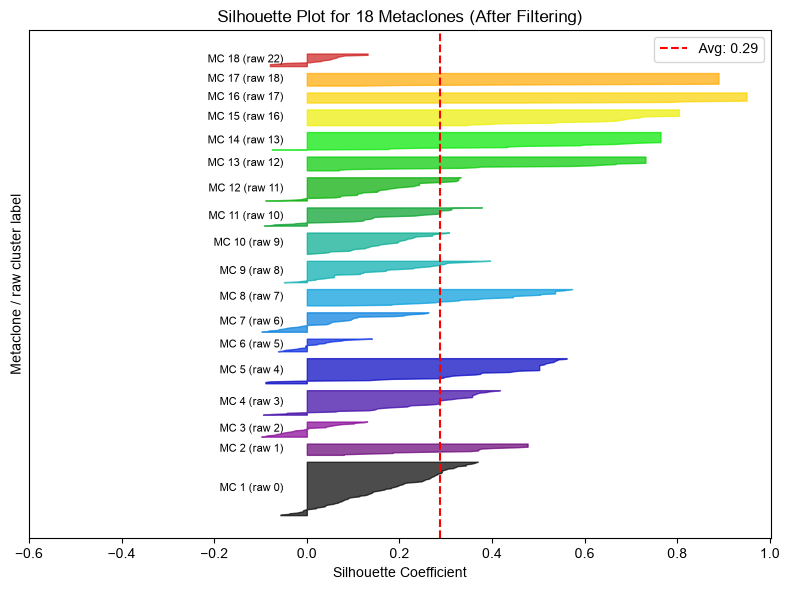

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/silhouette_after_filtering.svg
/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/silhouette_after_filtering.png
{'plotted_clones': 566, 'plotted_metaclones': 18, 'mean_of_plotted_silhouettes': 0.2884772022436195}


In [14]:
# These are the retained clones' original fitted scores, not scores recomputed
# on the smaller cohort. Keep the same raw-cluster colour identity as above.
all_raw_ids_after = np.sort(np.unique(np.asarray(labels)))
retained_mask = np.asarray(keep, dtype=bool)
raw_labels_after = np.asarray(labels)[retained_mask]
scores_after = np.asarray(clone_silhouettes, dtype=float)[retained_mask]
display_ids_after = np.asarray(metaclones)
assert len(raw_labels_after) == len(scores_after) == len(display_ids_after)
assert len(scores_after) and np.isfinite(scores_after).all()
raw_ids_after = np.sort(np.unique(raw_labels_after))
raw_colours_after = {raw: mpl.colormaps['nipy_spectral'](i / len(all_raw_ids_after))
                     for i, raw in enumerate(all_raw_ids_after)}
raw_to_display_after = {}
for raw_id in raw_ids_after:
    mapped_ids = np.unique(display_ids_after[raw_labels_after == raw_id])
    assert len(mapped_ids) == 1, 'Each retained raw cluster must map to one display MC.'
    raw_to_display_after[raw_id] = mapped_ids[0]
assert len(np.unique(list(raw_to_display_after.values()))) == len(raw_ids_after)
average_after = float(scores_after.mean())
with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42, 'ps.fonttype': 42,
                     'font.family': 'sans-serif', 'font.sans-serif': ['Arial']}):
    fig, ax = plt.subplots(figsize=(8, 6))
    y_lower = 10
    for raw_id in raw_ids_after:
        values = np.sort(scores_after[raw_labels_after == raw_id])
        y_upper = y_lower + len(values)
        colour = raw_colours_after[raw_id]
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, values,
                         facecolor=colour, edgecolor=colour, alpha=0.7)
        ax.text(-0.05, y_lower + 0.5 * len(values),
                f'MC {raw_to_display_after[raw_id]} (raw {raw_id})',
                ha='right', va='center', fontsize=8)
        y_lower = y_upper + 10
    ax.axvline(x=average_after, color='red', linestyle='--',
               label=f'Avg: {average_after:.2f}')
    ax.set_title(f'Silhouette Plot for {len(raw_ids_after)} Metaclones (After Filtering)')
    ax.set_xlabel('Silhouette Coefficient')
    ax.set_ylabel('Metaclone / raw cluster label')
    ax.set_yticks([])
    ax.set_xticks([-0.6, -0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8, 1])
    ax.legend()
    fig.tight_layout()
    stem = OUT / 'silhouette_after_filtering'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show()
    print(stem.with_suffix('.svg'))
    print(stem.with_suffix('.png'))
    print({'plotted_clones': len(scores_after), 'plotted_metaclones': len(raw_ids_after),
           'mean_of_plotted_silhouettes': average_after})


### Consensus distance heatmap

The dense matrix is embedded at 600 dpi in the SVG; boundary lines and text remain editable.

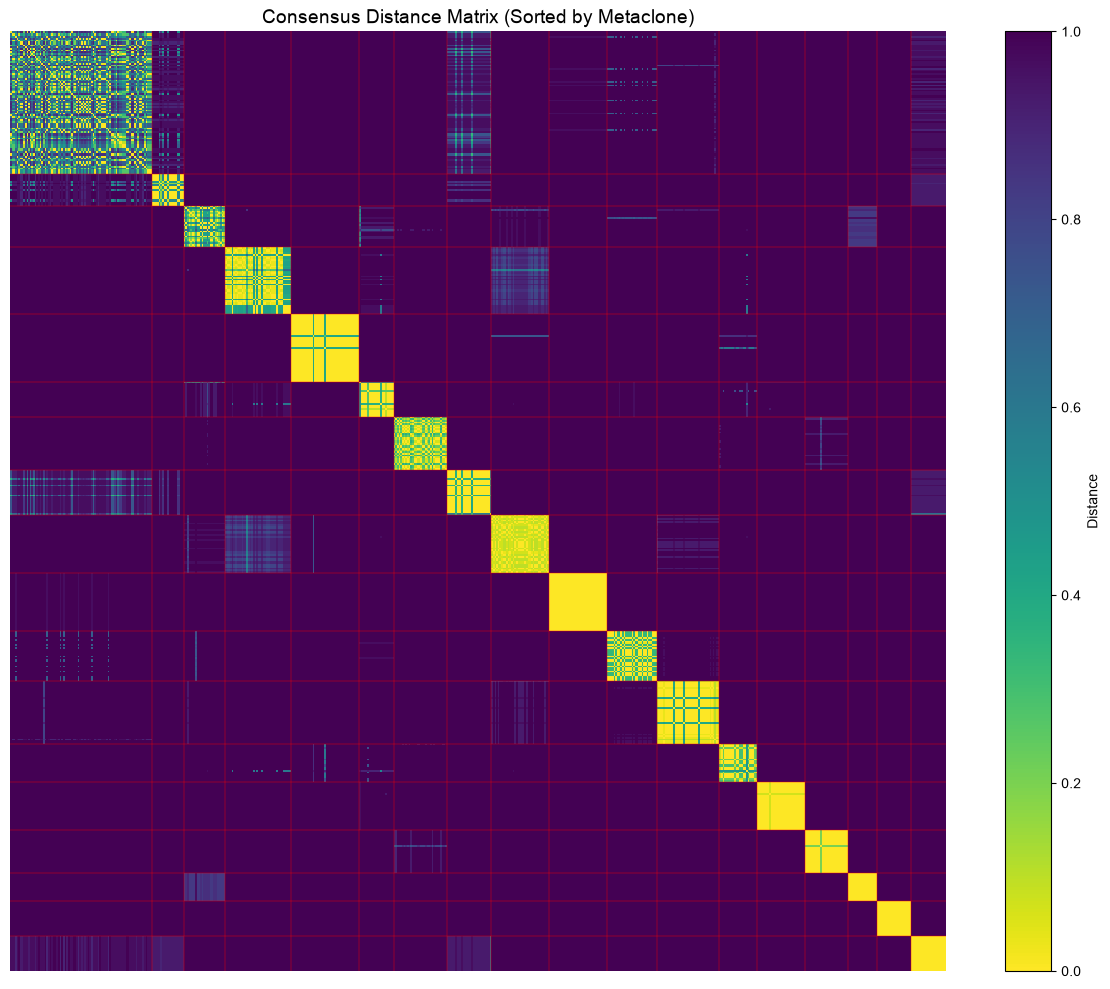

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/consensus_distance_heatmap.svg
/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/consensus_distance_heatmap.png
{'clones': 566, 'metaclones': 18, 'boundary_edges': [86, 105, 130, 170, 211, 232, 264, 291, 326, 361, 391, 429, 452, 481, 507, 524, 545], 'SVG_marks': '600-dpi matrix; vector text and boundaries'}


In [15]:
# Use the existing consensus distances and retained display IDs; do not refit.
heatmap_keep = np.asarray(keep, dtype=bool)
heatmap_labels = np.asarray(metaclones)
heatmap_distance = np.asarray(distance)[np.ix_(heatmap_keep, heatmap_keep)]
assert heatmap_distance.shape == (len(heatmap_labels), len(heatmap_labels))
assert len(heatmap_labels) and np.isfinite(heatmap_distance).all()
heatmap_order = np.argsort(heatmap_labels, kind='stable')
sorted_distance = heatmap_distance[np.ix_(heatmap_order, heatmap_order)]
sorted_heatmap_labels = heatmap_labels[heatmap_order]
# pcolormesh cells span integer edges; a change after index b is at b + 1.
heatmap_boundaries = np.flatnonzero(sorted_heatmap_labels[1:] != sorted_heatmap_labels[:-1]) + 1
with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42, 'ps.fonttype': 42,
                     'font.family': 'sans-serif', 'font.sans-serif': ['Arial']}):
    fig, ax = plt.subplots(figsize=(12, 10))
    heatmap = ax.pcolormesh(sorted_distance, cmap='viridis_r', shading='flat',
                           vmin=float(sorted_distance.min()), vmax=float(sorted_distance.max()),
                           rasterized=True, edgecolors='none', antialiased=False)
    ax.set_xlim(0, len(heatmap_labels))
    ax.set_ylim(len(heatmap_labels), 0)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    colourbar = fig.colorbar(heatmap, ax=ax)
    colourbar.set_label('Distance')
    if colourbar.solids is not None:
        colourbar.solids.set_rasterized(False)
    for boundary in heatmap_boundaries:
        ax.axhline(y=int(boundary), color='red', linewidth=0.3)
        ax.axvline(x=int(boundary), color='red', linewidth=0.3)
    ax.set_title('Consensus Distance Matrix (Sorted by Metaclone)', fontsize=14)
    fig.tight_layout()
    stem = OUT / 'consensus_distance_heatmap'
    fig.savefig(stem.with_suffix('.svg'), dpi=600, bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show()
    print(stem.with_suffix('.svg'))
    print(stem.with_suffix('.png'))
    print({'clones': len(heatmap_labels), 'metaclones': len(np.unique(heatmap_labels)),
           'boundary_edges': heatmap_boundaries.tolist(), 'SVG_marks': '600-dpi matrix; vector text and boundaries'})


### Clone distribution across metaclones

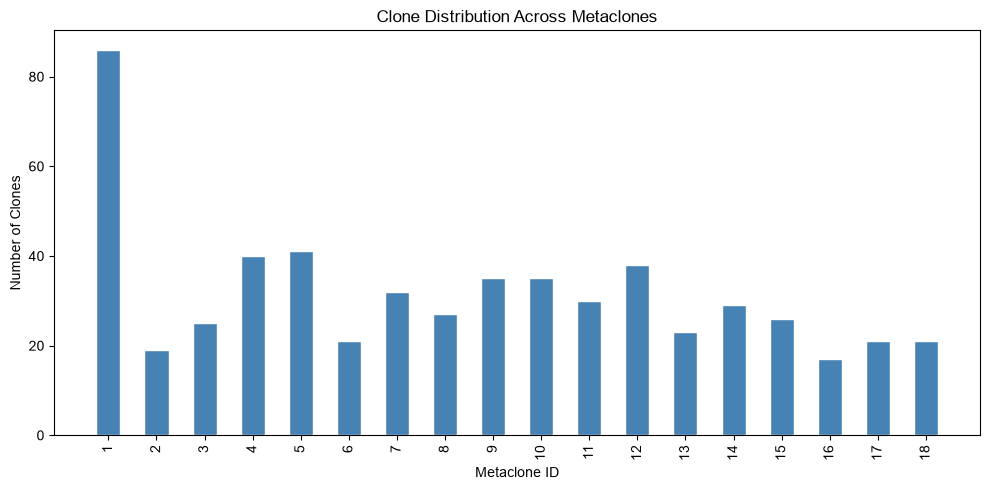

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_clone_counts.svg
/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_clone_counts.png


,clones
1,86
2,19
3,25
4,40
5,41
6,21
7,32
8,27
9,35
10,35


In [16]:
# Count retained clones, preserving the current public display IDs.
metaclone_clone_counts = pd.Series(np.asarray(metaclones)).value_counts().sort_index()
assert len(metaclone_clone_counts) and int(metaclone_clone_counts.sum()) == int(np.asarray(keep).sum())
with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42, 'ps.fonttype': 42,
                     'font.family': 'sans-serif', 'font.sans-serif': ['Arial']}):
    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(metaclone_clone_counts))
    ax.bar(x, metaclone_clone_counts.to_numpy(), width=0.5,
           color='steelblue', edgecolor='white')
    ax.set_xticks(x, [str(mc) for mc in metaclone_clone_counts.index], rotation=90)
    ax.set_xlabel('Metaclone ID')
    ax.set_ylabel('Number of Clones')
    ax.set_title('Clone Distribution Across Metaclones')
    fig.tight_layout()
    stem = OUT / 'metaclone_clone_counts'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show()
    print(stem.with_suffix('.svg'))
    print(stem.with_suffix('.png'))
    display(metaclone_clone_counts.rename('clones').to_frame())


## 7. Cell-state dynamics

Each bar shows the cell-state proportions within one metaclone and day. Metaclones have separate plot cells and SVG files.

### Metaclone 1

,cells,observed
day,,
2,107,True
4,358,True
6,1060,True


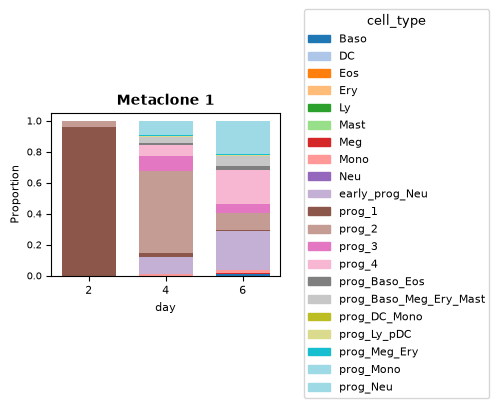

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_01_cell_state_dynamics


In [17]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 1
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 2

,cells,observed
day,,
2,20,True
4,40,True
6,56,True


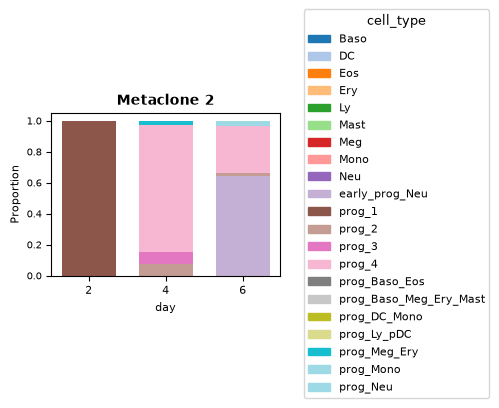

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_02_cell_state_dynamics


In [18]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 2
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 3

,cells,observed
day,,
2,32,True
4,121,True
6,234,True


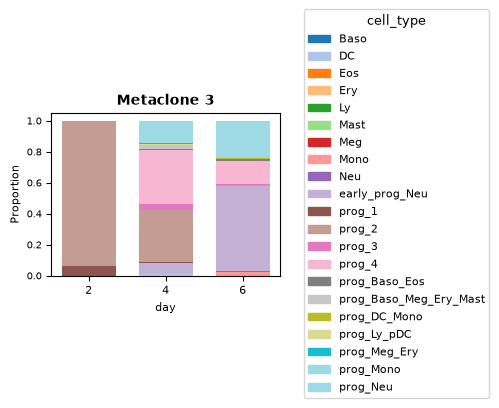

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_03_cell_state_dynamics


In [19]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 3
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 4

,cells,observed
day,,
2,54,True
4,147,True
6,350,True


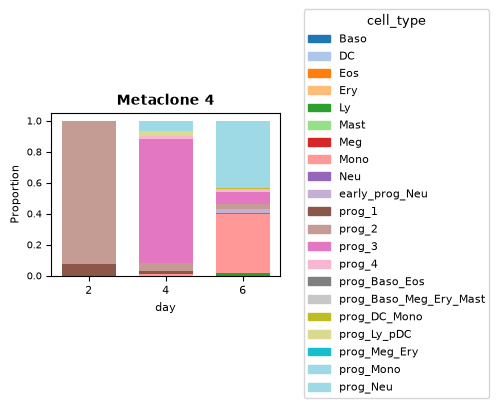

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_04_cell_state_dynamics


In [20]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 4
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 5

,cells,observed
day,,
2,58,True
4,347,True
6,162,True


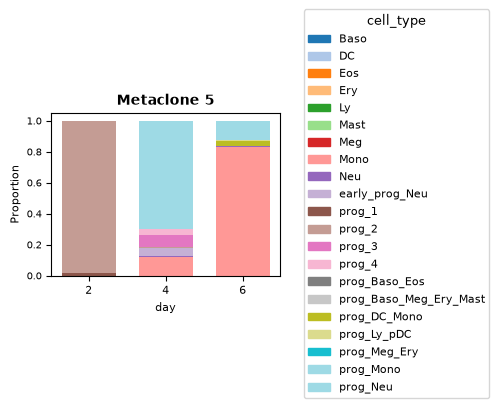

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_05_cell_state_dynamics


In [21]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 5
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 6

,cells,observed
day,,
2,30,True
4,79,True
6,57,True


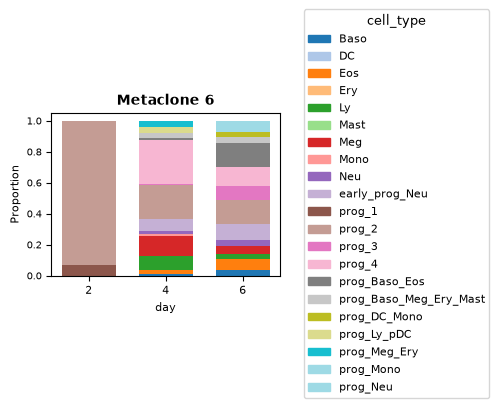

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_06_cell_state_dynamics


In [22]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 6
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 7

,cells,observed
day,,
2,52,True
4,385,True
6,772,True


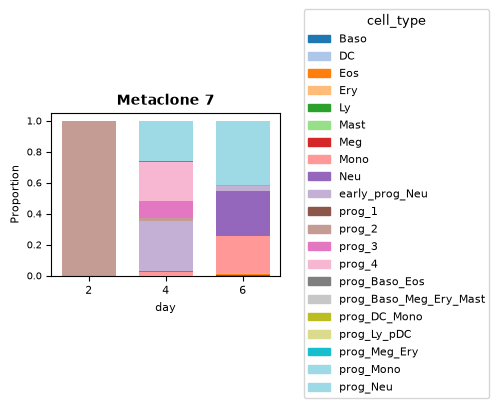

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_07_cell_state_dynamics


In [23]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 7
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 8

,cells,observed
day,,
2,31,True
4,64,True
6,170,True


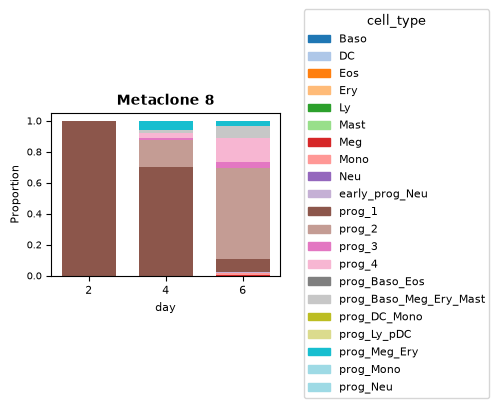

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_08_cell_state_dynamics


In [24]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 8
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 9

,cells,observed
day,,
2,41,True
4,171,True
6,427,True


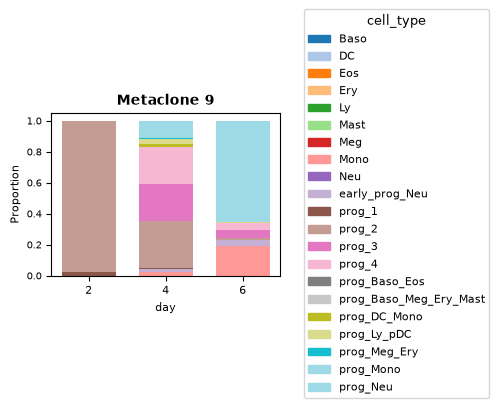

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_09_cell_state_dynamics


In [25]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 9
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 10

,cells,observed
day,,
2,47,True
4,126,True
6,371,True


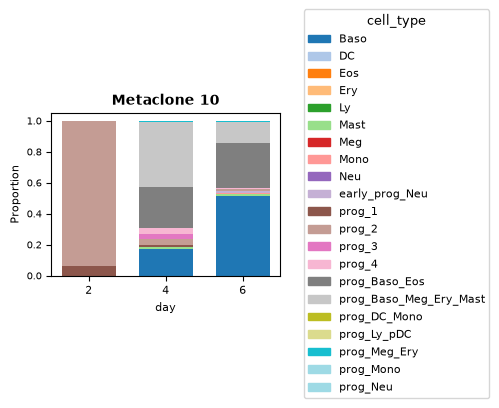

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_10_cell_state_dynamics


In [26]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 10
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 11

,cells,observed
day,,
2,39,True
4,69,True
6,184,True


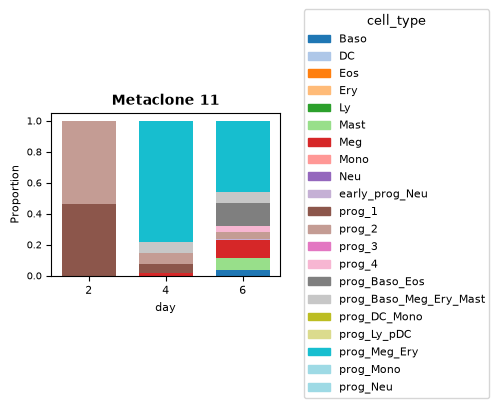

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_11_cell_state_dynamics


In [27]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 11
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 12

,cells,observed
day,,
2,51,True
4,74,True
6,287,True


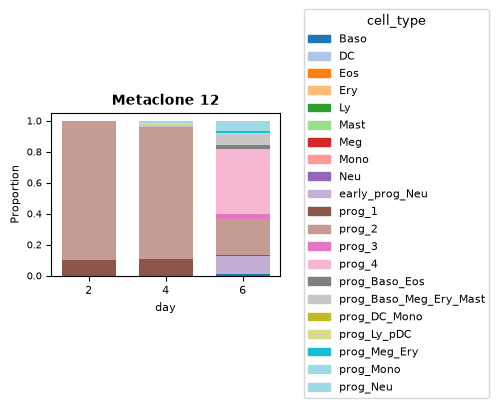

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_12_cell_state_dynamics


In [28]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 12
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 13

,cells,observed
day,,
2,37,True
4,85,True
6,5,True


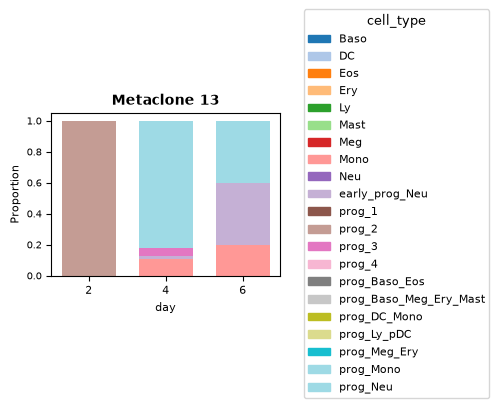

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_13_cell_state_dynamics


In [29]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 13
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 14

,cells,observed
day,,
2,51,True
4,112,True
6,10,True


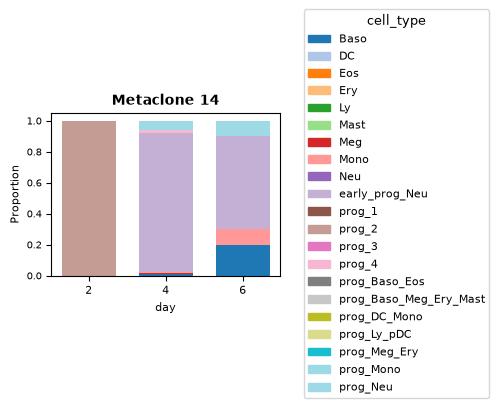

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_14_cell_state_dynamics


In [30]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 14
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 15

,cells,observed
day,,
2,41,True
4,152,True
6,210,True


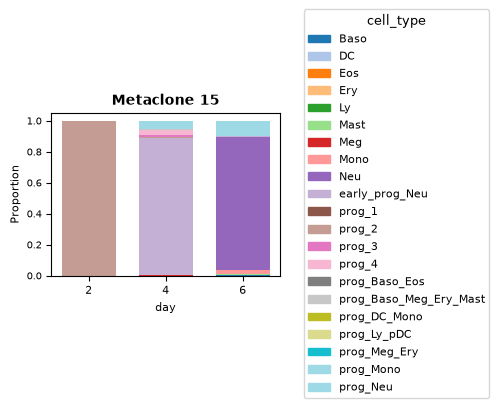

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_15_cell_state_dynamics


In [31]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 15
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 16

,cells,observed
day,,
2,17,True
4,37,True
6,61,True


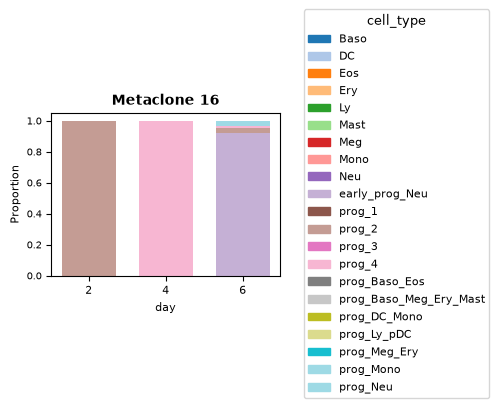

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_16_cell_state_dynamics


In [32]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 16
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 17

,cells,observed
day,,
2,39,True
4,43,True
6,8,True


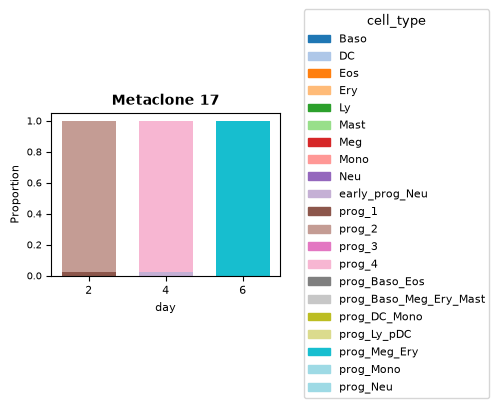

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_17_cell_state_dynamics


In [33]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 17
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


### Metaclone 18

,cells,observed
day,,
2,24,True
4,56,True
6,27,True


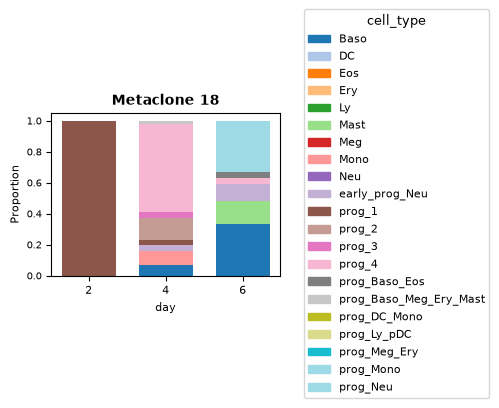

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/metaclone_dynamics/metaclone_18_cell_state_dynamics


In [34]:
# Cell-state composition for one metaclone, using the original tab20 mapping.
metaclone_number = 18
assigned_obs = adata.obs.loc[
    adata.obs['metaclone'].notna() & ~adata.obs['metaclone'].isin([-1, '-1'])
].copy()
features = sorted(assigned_obs['cell_type'].dropna().unique())
palette = plt.get_cmap('tab20')
feature_colors = {feature: palette(i / max(len(features) - 1, 1))
                  for i, feature in enumerate(features)}
metaclone_obs = assigned_obs.loc[assigned_obs['metaclone'].eq(metaclone_number)]
assert len(metaclone_obs), f'Metaclone {metaclone_number} has no assigned cells'
assert metaclone_obs[['day', 'cell_type']].notna().all().all()
counts = (metaclone_obs.groupby(['day', 'cell_type'], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=DAYS, columns=features, fill_value=0))
totals = counts.sum(axis=1)
observed_days = totals.gt(0)
# Absent states within an observed day are zero; days with no cells have no proportion.
proportions = counts.div(totals.where(observed_days), axis=0)
assert np.allclose(proportions.loc[observed_days].sum(axis=1), 1)
display(pd.DataFrame({'cells': totals, 'observed': observed_days}))

with mpl.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'font.family': 'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(3, 2.5))
    x = np.arange(len(DAYS))
    bottom = np.zeros(len(DAYS), dtype=float)
    for feature in features:
        heights = proportions[feature].to_numpy(dtype=float)
        ax.bar(x[observed_days], heights[observed_days],
               bottom=bottom[observed_days], color=feature_colors[feature],
               label=str(feature), width=0.7)
        bottom[observed_days] += heights[observed_days]
    for position in np.flatnonzero(~observed_days.to_numpy()):
        ax.text(position, 0.03, 'No cells', ha='center', va='bottom',
                fontsize=7, rotation=90, color='0.4')
    ax.set_title(f'Metaclone {metaclone_number}', fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(day) for day in DAYS], fontsize=8)
    ax.set_xlabel('day', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='y', labelsize=7)
    handles = [plt.Rectangle((0, 0), 1, 1, color=feature_colors[feature])
               for feature in features]
    fig.legend(handles, [str(feature) for feature in features], title='cell_type',
               bbox_to_anchor=(1.01, 0.5), loc='center left', fontsize=8, title_fontsize=9)
    fig.tight_layout()
    stem = DYNAMICS / f'metaclone_{metaclone_number:02d}_cell_state_dynamics'
    fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


## 8. Day-2 gene expression

Following the original notebook, compare each metaclone with the other metaclones using Wilcoxon tests. Select up to five genes per group with adjusted P < 0.05 and log fold change > 1. The dotplot uses per-gene scaled mean expression, with dot size indicating the fraction of cells expressing the gene.

In [35]:
# Join expression to the metaclones identified above; no stored labels are used.
adata_day2 = ad.read_h5ad(DATA/'weinreb_day2_expression.h5ad')
assert adata_day2.obs_names.is_unique
assert set(adata_day2.obs_names) == set(adata.obs_names[adata.obs.day.eq(2)])
adata_day2.obs['metaclone'] = adata.obs['metaclone'].reindex(adata_day2.obs_names)
adata_day2 = adata_day2[adata_day2.obs.metaclone.notna()].copy()
adata_day2.obs['metaclone'] = adata_day2.obs.metaclone.astype(int).astype(str).astype('category')
sc.tl.rank_genes_groups(adata_day2,groupby='metaclone',method='wilcoxon',use_raw=False)
de_df = sc.get.rank_genes_groups_df(adata_day2,group=None)
de_df.to_csv(OUT/'day2_differential_expression.csv.gz',index=False)
print(f'{adata_day2.n_obs:,} Day-2 cells; {adata_day2.n_vars:,} genes')


771 Day-2 cells; 25,289 genes


/Users/HiroMacBook/Documents/ChronoClone/.runtime/chronoclone/lib/python3.11/site-packages/scanpy/tools/_dendrogram.py:138: UserWarning: You’re trying to run this on 25289 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  _choose_representation(adata, use_rep=use_rep, n_pcs=n_pcs)


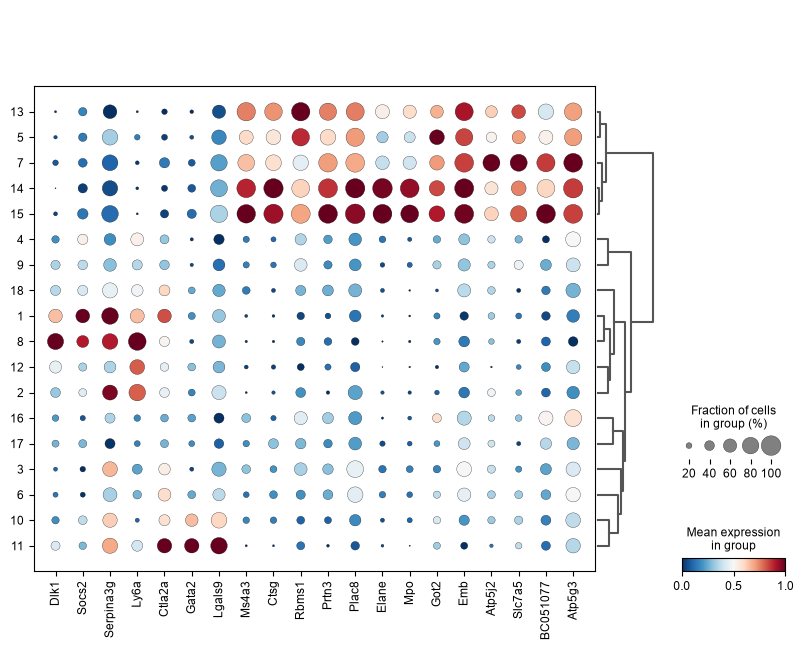

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/day2_metaclone_markers


In [36]:
# Select markers and calculate the dendrogram for this dotplot.
filtered_de = de_df[(de_df.pvals_adj < 0.05) & (de_df.logfoldchanges > 1)].copy()
marker_genes = filtered_de.groupby('group',observed=True).head(5)['names'].unique().tolist()
assert marker_genes, 'No genes pass the original marker filters.'
sc.tl.dendrogram(adata_day2,groupby='metaclone',use_raw=False)
filtered_de.to_csv(OUT/'day2_marker_genes.csv.gz',index=False)
with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'Arial'}):
    dotplot = sc.pl.dotplot(adata_day2,var_names=marker_genes,groupby='metaclone',
        standard_scale='var',cmap='RdBu_r',dendrogram=True,use_raw=False,return_fig=True)
    dotplot.make_figure()
    fig = dotplot.fig
    stem = OUT/'day2_metaclone_markers'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=200,bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


## 9. Plot a density UMAP

Rows are days and columns are metaclones. Gray points show all cells. Color counts how many of a cell's 100 nearest neighbors share its metaclone and day. Neighbors are selected from all cells. Each metaclone column shares one color scale across days; `n` is its number of clones.

The cell below shows the calculation and figure construction. It adds no lineage labels or family bars.

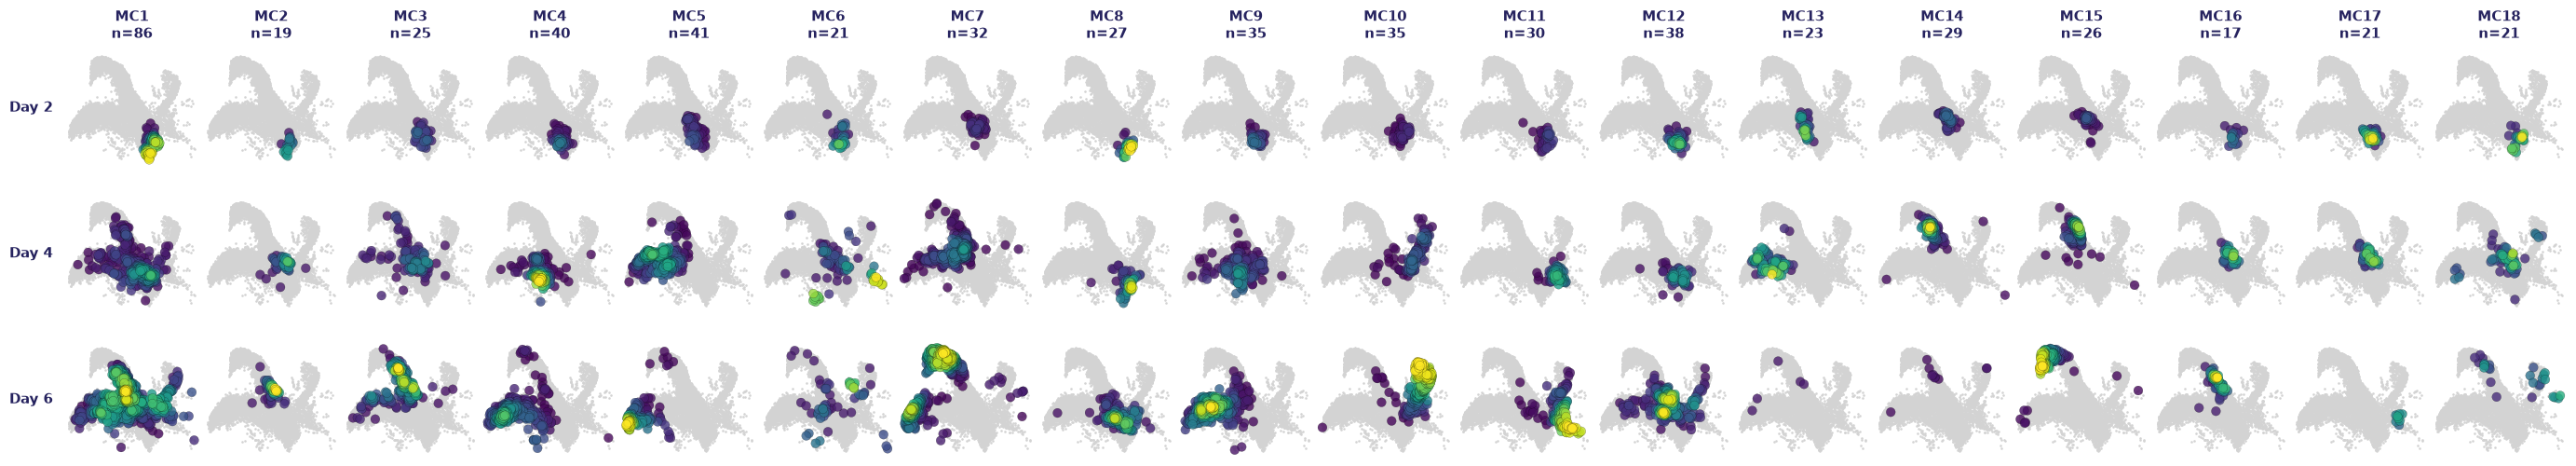

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/weinreb_metaclone_density_umap


In [37]:
# Calculate local density on the stored UMAP.
U = np.asarray(adata.obsm['X_umap'],dtype=float)
mc = adata.obs.metaclone
mc_order = sorted(mc.dropna().unique())
neighbor_index = NearestNeighbors(n_neighbors=min(100,len(U)),algorithm='ball_tree').fit(U)
neighbors = neighbor_index.kneighbors(U,return_distance=False)
groups, maxima = {}, {}
for m in mc_order:
    maxima[m] = 5
    for day in DAYS:
        mask = (mc.eq(m) & adata.obs.day.eq(day)).fillna(False).to_numpy(dtype=bool)
        density = mask[neighbors[mask]].sum(axis=1)
        groups[m,day] = (U[mask],density)
        if len(density): maxima[m] = max(maxima[m],density.max())

# Draw days × metaclones with one color scale per column.
with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    size = (1.55*len(mc_order),5.5)
    fig, axes = plt.subplots(len(DAYS),len(mc_order),figsize=size,squeeze=False)
    low, high = U.min(axis=0)-1, U.max(axis=0)+1
    for column,m in enumerate(mc_order):
        n_clones = adata.obs.loc[mc.eq(m),'LARRY_ID'].nunique()
        for row,day in enumerate(DAYS):
            ax = axes[row,column]
            ax.scatter(U[:,0],U[:,1],s=3.5,c='lightgrey',lw=0,rasterized=True,zorder=0)
            coordinates,density = groups[m,day]
            if len(density):
                order = np.argsort(density,kind='stable')
                ax.scatter(coordinates[order,0],coordinates[order,1],c=density[order],
                    cmap='viridis',s=50,alpha=0.8,edgecolors='black',linewidths=0.15,
                    vmin=0,vmax=maxima[m],rasterized=False,zorder=2)
            ax.set_aspect('equal')
            ax.set_xlim(low[0],high[0]); ax.set_ylim(low[1],high[1])
            ax.axis('off')
            if column==0:
                ax.text(-0.08,0.5,f'Day {day}',transform=ax.transAxes,fontsize=11,
                        color='#26235F',fontweight='bold',ha='right',va='center')
            if row==0:
                ax.set_title(f'MC{int(m)}\nn={n_clones}',fontsize=11,color='#26235F',fontweight='bold',pad=10)
    fig.subplots_adjust(left=max(0.03,0.62/size[0]),right=1-0.18/size[0],
                        top=1-0.7/size[1],bottom=0.15/size[1],wspace=0.02,hspace=0.03)
    stem = OUT/'weinreb_metaclone_density_umap'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.pdf'),dpi=300,bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=600,bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


## 10. Cell states after continuity filtering

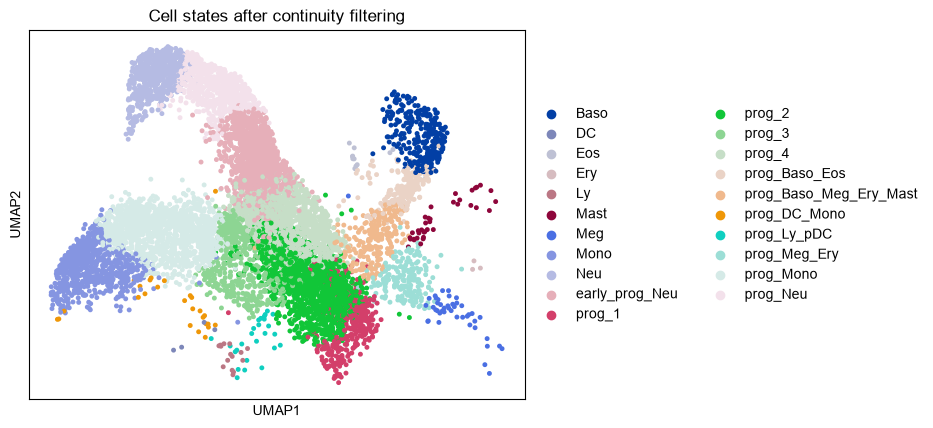

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/filtered_cell_state_umap


In [38]:
# Select states and coordinates for this original annotation view.
plot_cells = adata.obs
coordinates = np.asarray(adata.obsm['X_umap'])
state_order = plot_inputs['annotation_umap']['category_order']
if not False:
    state_order = [state for state in state_order if plot_cells['cell_type'].eq(state).any()]
state_colors = plot_inputs['annotation_umap']['palette_by_label']
selected_states = state_order
plot_obs = pd.DataFrame(index=plot_cells.index)
plot_obs['cell_type'] = pd.Categorical(plot_cells['cell_type'],categories=state_order)
annotation_view = ad.AnnData(X=sparse.csr_matrix((len(plot_obs),0)),obs=plot_obs)
annotation_view.obsm['X_umap'] = coordinates
annotation_view.uns['cell_type_colors'] = [state_colors[state] for state in state_order]
with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'Arial'}):
    fig, ax = plt.subplots(figsize=(6.4,4.8))
    sc.pl.umap(annotation_view,color='cell_type',groups=selected_states,
        s=50,legend_loc="right margin",
        title='Cell states after continuity filtering',ax=ax,show=False)
    stem = OUT/'filtered_cell_state_umap'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=200,bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


## Use the plotting function

The package provides the same density UMAP as a reusable function:

```python
fig, axes = cc.plot_metaclone_density_umap(
    adata, time_order=[2, 4, 6], neighbor_reference="all"
)
fig.savefig("density_umap.svg", bbox_inches="tight")
```

The output folder contains clone assignments, the threshold sweep, the run settings, and all figures. The cell-state dynamics SVGs are in `results/metaclone_dynamics/`. Metaclone IDs refer to this run. The [source notes](../examples/weinreb/data/README.md) explain the saved author workflow and its historical partition.